# Sienna Cafe Analysis
This dataset contains restaurant-related information with a combination of numerical, categorical and geographical data types, along with missing values and inconsistencies. 

It includes details about restaurant locations, cuisines, pricing, table booking, online delivery, ratings and customer votes. 

Data cleaning and preprocessing should be performed before conducting Exploratory Data Analysis and visualization.

In [59]:
#importing the required libraries
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
sns.set_theme(style="whitegrid") # Set the style for seaborn plots

## Data Checking

In [60]:
# reading data
df = pd.read_csv("sienna_cafe.csv")

In [61]:
#head
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [62]:
#tail
df.tail()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
9546,5915730,Naml۱ Gurme,208,��stanbul,"Kemanke�� Karamustafa Pa��a Mahallesi, R۱ht۱m ...",Karak�_y,"Karak�_y, ��stanbul",28.977392,41.022793,Turkish,...,Turkish Lira(TL),No,No,No,No,3,4.1,Green,Very Good,788
9547,5908749,Ceviz A��ac۱,208,��stanbul,"Ko��uyolu Mahallesi, Muhittin ��st�_nda�� Cadd...",Ko��uyolu,"Ko��uyolu, ��stanbul",29.041297,41.009847,"World Cuisine, Patisserie, Cafe",...,Turkish Lira(TL),No,No,No,No,3,4.2,Green,Very Good,1034
9548,5915807,Huqqa,208,��stanbul,"Kuru�_e��me Mahallesi, Muallim Naci Caddesi, N...",Kuru�_e��me,"Kuru�_e��me, ��stanbul",29.034640,41.055817,"Italian, World Cuisine",...,Turkish Lira(TL),No,No,No,No,4,3.7,Yellow,Good,661
9549,5916112,A���k Kahve,208,��stanbul,"Kuru�_e��me Mahallesi, Muallim Naci Caddesi, N...",Kuru�_e��me,"Kuru�_e��me, ��stanbul",29.036019,41.057979,Restaurant Cafe,...,Turkish Lira(TL),No,No,No,No,4,4.0,Green,Very Good,901
9550,5927402,Walter's Coffee Roastery,208,��stanbul,"Cafea��a Mahallesi, Bademalt۱ Sokak, No 21/B, ...",Moda,"Moda, ��stanbul",29.026016,40.984776,Cafe,...,Turkish Lira(TL),No,No,No,No,2,4.0,Green,Very Good,591


In [63]:
#checking datatypes
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   str    
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   str    
 4   Address               9551 non-null   str    
 5   Locality              9551 non-null   str    
 6   Locality Verbose      9551 non-null   str    
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   str    
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   str    
 12  Has Table booking     9551 non-null   str    
 13  Has Online delivery   9551 non-null   str    
 14  Is delivering now     9551 non-null   str    
 15  Switch to order menu  9551 non-n

In [64]:
df.columns #checking the available columns

Index(['Restaurant ID', 'Restaurant Name', 'Country Code', 'City', 'Address',
       'Locality', 'Locality Verbose', 'Longitude', 'Latitude', 'Cuisines',
       'Average Cost for two', 'Currency', 'Has Table booking',
       'Has Online delivery', 'Is delivering now', 'Switch to order menu',
       'Price range', 'Aggregate rating', 'Rating color', 'Rating text',
       'Votes'],
      dtype='str')

In [65]:
#determining the number of rows and columns in the dataset
df.shape #data ha 9551 rows and 21 columns

(9551, 21)

## Data Cleaning

In [66]:
# checking for duplicates
df.duplicated().any()

np.False_

In [67]:
# checking for missing values
df.isnull().any()

Restaurant ID           False
Restaurant Name         False
Country Code            False
City                    False
Address                 False
Locality                False
Locality Verbose        False
Longitude               False
Latitude                False
Cuisines                 True
Average Cost for two    False
Currency                False
Has Table booking       False
Has Online delivery     False
Is delivering now       False
Switch to order menu    False
Price range             False
Aggregate rating        False
Rating color            False
Rating text             False
Votes                   False
dtype: bool

In [68]:
df.isnull().sum().sort_values(ascending=False) #checking the sum of missing values in the columns

Cuisines                9
Restaurant Name         0
Country Code            0
City                    0
Restaurant ID           0
Address                 0
Locality                0
Longitude               0
Locality Verbose        0
Latitude                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [69]:
# dropping all missing values in the dataset
df1 = df.dropna()
print(df1)

      Restaurant ID           Restaurant Name  Country Code              City  \
0           6317637          Le Petit Souffle           162       Makati City   
1           6304287          Izakaya Kikufuji           162       Makati City   
2           6300002    Heat - Edsa Shangri-La           162  Mandaluyong City   
3           6318506                      Ooma           162  Mandaluyong City   
4           6314302               Sambo Kojin           162  Mandaluyong City   
...             ...                       ...           ...               ...   
9546        5915730               Naml۱ Gurme           208         ��stanbul   
9547        5908749              Ceviz A��ac۱           208         ��stanbul   
9548        5915807                     Huqqa           208         ��stanbul   
9549        5916112               A���k Kahve           208         ��stanbul   
9550        5927402  Walter's Coffee Roastery           208         ��stanbul   

                           

In [70]:
# Verifying thatthere's longer any null values in the dataset
print(df1.isnull().sum())

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64


In [71]:
#Check for duplicates
df1.duplicated().value_counts()

False    9542
Name: count, dtype: int64

In [72]:
#Check the distribution of the rating:
print((df1["Aggregate rating"] == 0).sum(), "restaurants have rating 0.0")

2148 restaurants have rating 0.0


### renaming columns

In [73]:
df1.columns = (df1.columns
                 .str.strip()                          # remove stray spaces
                 .str.lower()                          # lowercase everything
                 .str.replace(r"[^a-z0-9]+", "_", regex=True))  # junk -> "_"
print(list(df1.columns))

['restaurant_id', 'restaurant_name', 'country_code', 'city', 'address', 'locality', 'locality_verbose', 'longitude', 'latitude', 'cuisines', 'average_cost_for_two', 'currency', 'has_table_booking', 'has_online_delivery', 'is_delivering_now', 'switch_to_order_menu', 'price_range', 'aggregate_rating', 'rating_color', 'rating_text', 'votes']


In [74]:
# convert country code into country name
COUNTRY = {1: "India", 14: "Australia", 30: "Brazil", 37: "Canada",
           94: "Indonesia", 148: "New Zealand", 162: "Philippines",
           166: "Qatar", 184: "Singapore", 189: "South Africa",
           191: "Sri Lanka", 208: "Turkey", 214: "UAE",
           215: "United Kingdom", 216: "United States"}
df1["country"] = df1["country_code"].map(COUNTRY)
print(df1["country"].isna().sum(), "rows with an unknown country code")

0 rows with an unknown country code


In [75]:
#fix the currency column by removing the currency symbol and converting it to float
df1["currency"] = df1["currency"].str.replace(r"Pounds\(.*\)",
                                                  "Pounds(GBP)", regex=True)
# .loc[row_condition, column] = value  ->  "for rows where X, set column to Y"
df1.loc[df1["country"] == "Philippines", "currency"] = "Philippine Peso(PHP)"


In [76]:
# Pull the short code out of the brackets: "Dollar($)" -> "$"
df1["currency_code"] = df1["currency"].str.extract(r"\(([^)]+)\)")
print(df1["currency_code"].value_counts())

currency_code
Rs.    8652
$       513
GBP      80
R$       60
AED      60
R        60
TL       34
PHP      22
IDR      21
QR       20
LKR      20
Name: count, dtype: int64


In [77]:
# Make costs comparable across countries
#Convert "average cost for two" into one common currency (USD).

USD_PER_UNIT = {"Rs.": 0.012, "$": 1.0, "GBP": 1.3, "R$": 0.19,
                "AED": 0.272, "R": 0.055, "TL": 0.05, "P": 0.073,
                "IDR": 0.000064, "QR": 0.275, "LKR": 0.0033, "PHP": 0.018}
df1["fx"] = df1["currency_code"].map(USD_PER_UNIT)# New Zealand uses "$" too, but a NZ dollar is worth less than a US dollar:
df1.loc[df1["country"] == "New Zealand", "fx"] = 0.60
df1["cost_usd"] = df1["average_cost_for_two"] * df1["fx"]

# A cost of 0 is not "free dinner", it's missing data. Convert to NaN.
# NaN = "Not a Number" = pandas's way of writing "blank / unknown".
df1.loc[df1["average_cost_for_two"] == 0, "cost_usd"] = np.nan

In [78]:
#Fix the fake zero ratings
# #Make a new "rating" column where 0.0 becomes NaN (unknown).

df1["rating"] = df1["aggregate_rating"].replace(0, np.nan)
df1["is_rated"] = df1["rating"].notna()   # True/False helper column

In [79]:
#Fix fake coordinates
# Longitude 0, Latitude 0 is a spot in the ocean off Africa. No restaurant is
# there: it's a placeholder for "location unknown". Blank it out.
no_location = (df1["longitude"] == 0) & (df1["latitude"] == 0)
print(no_location.sum(), "restaurants have no real location")
df1.loc[no_location, ["longitude", "latitude"]] = np.nan

497 restaurants have no real location


In [80]:
#Turn "Yes"/"No" into True/False
for col in ["has_table_booking", "has_online_delivery", "is_delivering_now"]:
    df1[col] = df1[col].eq("Yes")   # .eq("Yes") -> True where value=="Yes"

In [81]:
#Drop a useless column
# "switch_to_order_menu" is "No" in every row. A column that never changes tells you nothing, so it's just clutter.
print(df1["switch_to_order_menu"].unique())
df1 = df1.drop(columns="switch_to_order_menu")

<StringArray>
['No']
Length: 1, dtype: str


In [82]:
# handle the "cuisines" column
# The "cuisines" column is a comma-separated list of cuisines. Each restaurant can list several cuisines in ONE cell: "French, Japanese".
# To analyse "Japanese" restaurants properly split them apart.
df1["cuisines"] = df1["cuisines"].fillna("Unknown")   # 9 blanks
df1["cuisine_list"] = df1["cuisines"].str.split(r"\s*,\s*")  # -> a list
df1["primary_cuisine"] = df1["cuisine_list"].str[0]   # first listed one
df1["n_cuisines"] = df1["cuisine_list"].apply(len)    # how many listed

In [83]:
#print the cleaned dataset
print(df1.head())

   restaurant_id         restaurant_name  country_code              city  \
0        6317637        Le Petit Souffle           162       Makati City   
1        6304287        Izakaya Kikufuji           162       Makati City   
2        6300002  Heat - Edsa Shangri-La           162  Mandaluyong City   
3        6318506                    Ooma           162  Mandaluyong City   
4        6314302             Sambo Kojin           162  Mandaluyong City   

                                             address  \
0  Third Floor, Century City Mall, Kalayaan Avenu...   
1  Little Tokyo, 2277 Chino Roces Avenue, Legaspi...   
2  Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...   
3  Third Floor, Mega Fashion Hall, SM Megamall, O...   
4  Third Floor, Mega Atrium, SM Megamall, Ortigas...   

                                     locality  \
0   Century City Mall, Poblacion, Makati City   
1  Little Tokyo, Legaspi Village, Makati City   
2  Edsa Shangri-La, Ortigas, Mandaluyong City   
3      SM 

In [84]:
#data verification
print(df1.isna().sum()[lambda s: s > 0])

#these are values left blank on purpose as they are not as useful for analysis. The rest of the columns should have no missing values.

longitude     497
latitude      497
cost_usd       15
rating       2148
dtype: int64


## Outlier Checks

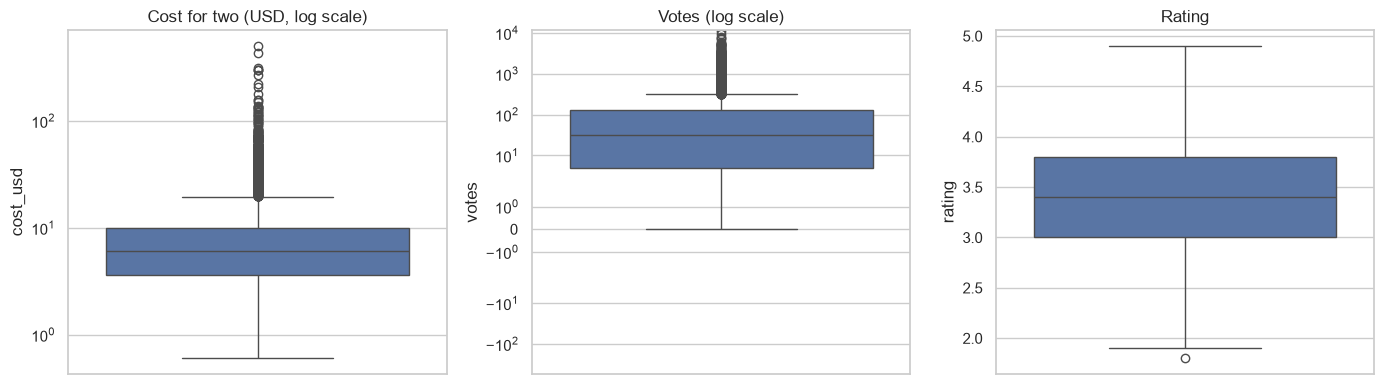

In [85]:
#using boxplots
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sns.boxplot(y=df1["cost_usd"].dropna(), ax=axes[0]);  axes[0].set_yscale("log")
axes[0].set_title("Cost for two (USD, log scale)")
sns.boxplot(y=df1["votes"], ax=axes[1]);              axes[1].set_yscale("symlog")
axes[1].set_title("Votes (log scale)")
sns.boxplot(y=df1["rating"].dropna(), ax=axes[2]);    axes[2].set_title("Rating")
plt.tight_layout(); plt.show()


In [86]:
# using quantiles
def iqr_bounds(series, k=1.5):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - k * iqr, q3 + k * iqr

summary = []
for col in ["cost_usd", "votes", "rating"]:
    s = df1[col].dropna()                # ignore blanks
    low, high = iqr_bounds(s)
    n_out = ((s < low) | (s > high)).sum() # True counts as 1, so sum() counts
    summary.append({"column": col, "lower": round(low, 2), "upper": round(high, 2),
                    "outliers": n_out, "pct": round(100 * n_out / len(s), 1)})
print(pd.DataFrame(summary))


     column  lower  upper  outliers   pct
0  cost_usd   -6.0   19.6      1047  11.0
1     votes -182.5  317.5      1131  11.9
2    rating    1.8    5.0         1   0.0


In [87]:
#by checking rows
cols = ["restaurant_name", "city", "country", "average_cost_for_two",
        "currency_code", "cost_usd", "price_range"]
print(df1.nlargest(8, "cost_usd")[cols])
# These are fine-dining places in Singapore/London, with price_range = 4. Real!
# The raw max of 800,000 looked scary, but it's Indonesian Rupiah (~$51), so
# it was a CURRENCY issue, not a bad value. 

print(df1.nlargest(8, "votes")[["restaurant_name", "city", "votes", "rating"]])
# Famous, busy places. Real too.

               restaurant_name       city         country  \
458           Restaurant Andre  Singapore       Singapore   
460                       Jaan  Singapore       Singapore   
461      Rhubarb Le Restaurant  Singapore       Singapore   
456                  Sky On 57  Singapore       Singapore   
469            Summer Pavilion  Singapore       Singapore   
9384  Restaurant Gordon Ramsay     London  United Kingdom   
457       Cut By Wolfgang Puck  Singapore       Singapore   
468                     Colony  Singapore       Singapore   

      average_cost_for_two currency_code  cost_usd  price_range  
458                    500             $     500.0            4  
460                    430             $     430.0            4  
461                    315             $     315.0            4  
456                    300             $     300.0            4  
469                    300             $     300.0            4  
9384                   230           GBP     299.0    

In [88]:
# by checking within a group
# $20 for two is cheap in London but expensive in India. So compare each
# restaurant only against others in ITS OWN country. transform() runs the
# function per group and returns one answer per original row.
def flag_extreme(series):
    low, high = iqr_bounds(series.dropna(), k=3)   # k=3: only the extreme ones
    return (series < low) | (series > high)

df1["cost_outlier"] = df1.groupby("country")["cost_usd"].transform(flag_extreme)
print(df1["cost_outlier"].sum(), "extreme cost outliers within their country")
print(df1[df1["cost_outlier"]].groupby("country").size())

342 extreme cost outliers within their country
country
Australia           5
India             329
Indonesia           2
Philippines         1
South Africa        2
Turkey              1
United Kingdom      2
dtype: int64


In [89]:
#crosscheck against another column
# Price range (1-4) and cost should agree. If median cost rises smoothly with
# price range, the cost data is trustworthy. A jump out of order = bad data.
print(df1.groupby("price_range")["cost_usd"].median().round(1))

price_range
1     3.6
2     7.2
3    15.6
4    30.0
Name: cost_usd, dtype: float64


In [90]:
# We keep every row and just mark suspects in `cost_outlier`. Later you can
# compare results with and without them, e.g.:
#   clean[~clean["cost_outlier"]]["cost_usd"].mean()   vs   ...[all rows]
# And for skewed columns, prefer the MEDIAN over the mean: it ignores outliers.
print("Mean cost :", df1["cost_usd"].mean().round(2))
print("Median    :", df1["cost_usd"].median().round(2))

Mean cost : 9.93
Median    : 6.0


## Univariate EDA

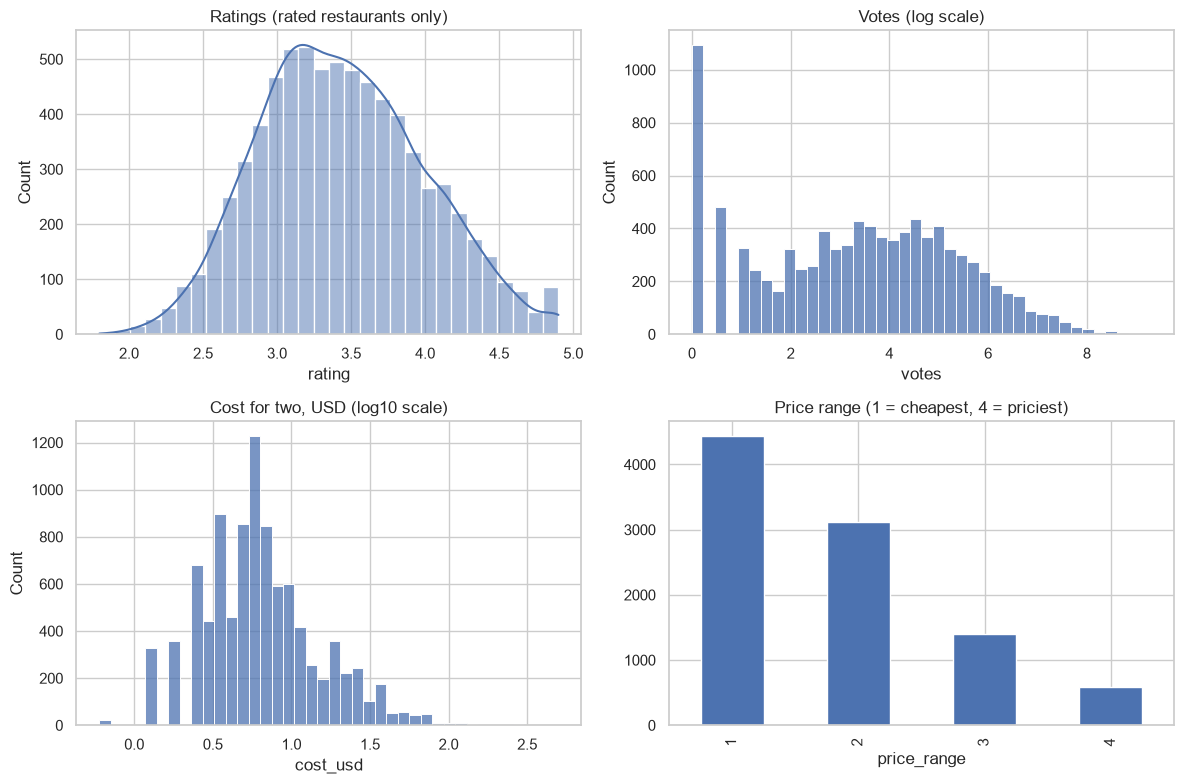

Votes  mean: 156.8 | median: 31.0


In [91]:
#check the shape of indicidual important variables
fig, axes = plt.subplots(2, 2, figsize=(12, 8))   # a 2x2 grid of charts

# Ratings (only real ones). A histogram counts how many fall in each bucket.
sns.histplot(df1["rating"].dropna(), bins=30, kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Ratings (rated restaurants only)")

# Votes: most restaurants have very few, a handful have thousands. That's a
# "long tail", so we use np.log1p (= log(1+x)) to squash it into view.
sns.histplot(np.log1p(df1["votes"]), bins=40, ax=axes[0, 1])
axes[0, 1].set_title("Votes (log scale)")

# Cost: same long-tail issue, so we use a log scale again.
sns.histplot(np.log10(df1["cost_usd"].dropna()), bins=40, ax=axes[1, 0])
axes[1, 0].set_title("Cost for two, USD (log10 scale)")

# Price range 1-4: a category, so a bar chart of counts.
df1["price_range"].value_counts().sort_index().plot.bar(
    ax=axes[1, 1], title="Price range (1 = cheapest, 4 = priciest)")

plt.tight_layout()
plt.show()

# Median vs mean: if they're very different, the data is skewed.
print("Votes  mean:", df1["votes"].mean().round(1),
      "| median:", df1["votes"].median())


### Where the restaurants are located - cities & countries


country
India             8652
United States      425
United Kingdom      80
Brazil              60
UAE                 60
South Africa        60
New Zealand         40
Turkey              34
Australia           24
Philippines         22
Indonesia           21
Singapore           20
Qatar               20
Sri Lanka           20
Canada               4
Name: count, dtype: int64
                   restaurants  avg_rating  median_cost_usd  delivery_share
country city                                                               
India   Gurgaon           1118    3.330674              6.0        0.380143
        New Delhi         5473    3.297381              4.8        0.272063
        Noida             1080    3.159626              5.4        0.337037
        Faridabad          251    3.103311              4.8        0.139442
                   restaurants  avg_rating  median_cost_usd  delivery_share
country city                                                               
India   Gurga

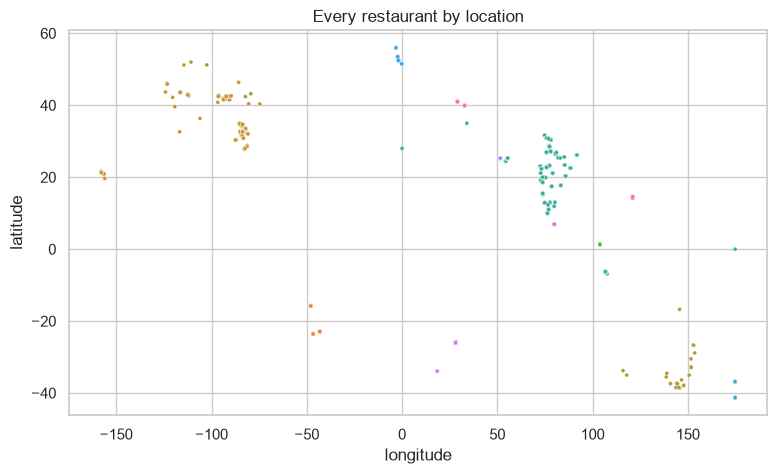

In [92]:
# .value_counts() = "count how many of each"
print(df1["country"].value_counts())
# Big finding: ~90% are in India. That means "overall averages" are really
# "India averages". Keep that in mind for every later conclusion!

# GROUPBY = "split the table by category, calculate something for each group".
# Pattern: df.groupby(column).agg(new_name=(source_column, function))
city_stats = (df1.groupby(["country", "city"])
                   .agg(restaurants=("restaurant_id", "size"),  # row count
                        avg_rating=("rating", "mean"),
                        median_cost_usd=("cost_usd", "median"),
                        delivery_share=("has_online_delivery", "mean"))
                   .query("restaurants >= 30")  # ignore tiny cities: an
                                                # average of 3 restaurants
                                                # is mostly luck.
                   .sort_values("avg_rating", ascending=False))
print(city_stats.head(10))   # best-rated cities
print(city_stats.tail(10))   # worst-rated cities

# A map made from nothing but longitude (x) and latitude (y):
plt.figure(figsize=(9, 5))
sns.scatterplot(data=df1.dropna(subset=["longitude"]),
                x="longitude", y="latitude", hue="country",
                s=8, legend=False)
plt.title("Every restaurant by location")
plt.show()

## Exploring cuisines

               restaurants  avg_rating  median_cost_usd
cuisine_list                                           
Indian                  70    4.156061             27.2
Sandwich                53    4.066038             25.0
Mediterranean          112    4.020000             19.2
Steak                   62    3.985484             40.0
Sushi                   75    3.973333             25.0
European               148    3.964384             21.8
Seafood                174    3.929825             25.0
Asian                  233    3.898684             18.0
Mexican                181    3.872989             12.0
Japanese               135    3.825373             22.8
              restaurants  avg_rating  median_cost_usd
cuisine_list                                          
Healthy Food          150    3.373723              6.0
North Indian         3960    3.295128              6.0
Street Food           562    3.285608              2.4
Chinese              2733    3.282280              6.

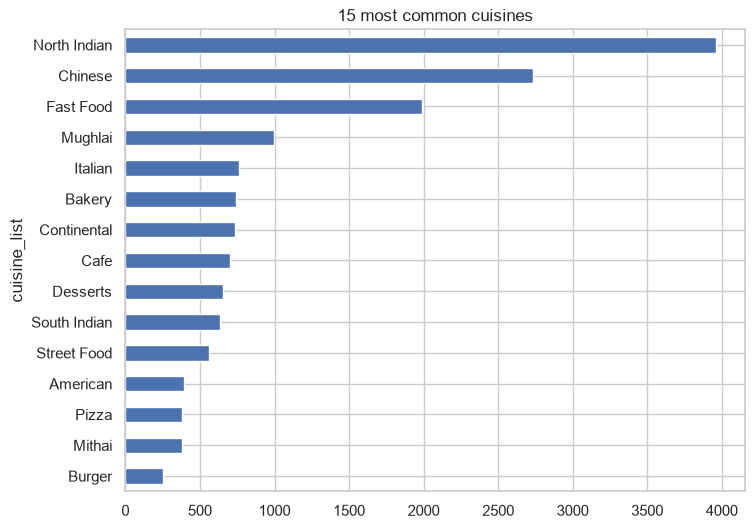

In [93]:
# .explode() turns a list column into one row PER item, so a restaurant
# listing 3 cuisines becomes 3 rows. Now we can group by cuisine.
by_cuisine = df1.explode("cuisine_list")

cuisine_stats = (by_cuisine.groupby("cuisine_list")
                 .agg(restaurants=("restaurant_id", "nunique"),  # unique count
                      avg_rating=("rating", "mean"),
                      median_cost_usd=("cost_usd", "median"))
                 .query("restaurants >= 50")   # again: ignore rare cuisines
                 .sort_values("avg_rating", ascending=False))

print(cuisine_stats.head(10))   # highest rated cuisines
print(cuisine_stats.tail(10))   # lowest rated cuisines

# Most common cuisines as a horizontal bar chart.
by_cuisine["cuisine_list"].value_counts().head(15).sort_values().plot.barh(
    figsize=(8, 6), title="15 most common cuisines")
plt.show()

## Rating Analysis

In [94]:
# From here on we only use RATED restaurants, because "unrated" has no
# rating to compare.
rated = df1[df1["is_rated"]].copy()# Compare groups. Table booking: yes vs no.
print(rated.groupby("has_table_booking")["rating"].agg(["mean", "count"]))
print(rated.groupby("has_online_delivery")["rating"].agg(["mean", "count"]))
print(rated.groupby("price_range")["rating"].agg(["mean", "median", "count"]))

                       mean  count
has_table_booking                 
False              3.413322   6283
True               3.587579   1111
                         mean  count
has_online_delivery                 
False                3.466720   5039
True                 3.381274   2355
                 mean  median  count
price_range                         
1            3.237692     3.2   2738
2            3.377167     3.4   2711
3            3.776715     3.8   1370
4            3.890957     3.9    575


In [95]:
# Check whether the difference is REAL or just random noise? Using a statistical test.
# Mann-Whitney U compares two groups without assuming bell-curve data.
with_booking = rated.loc[rated["has_table_booking"], "rating"]
without_booking = rated.loc[~rated["has_table_booking"], "rating"]   # ~ = NOT
result = stats.mannwhitneyu(with_booking, without_booking)
print("Booking vs not: difference =",
      round(with_booking.mean() - without_booking.mean(), 3),
      "| p-value =", result.pvalue)

# p-value is less than 0.05 hence here the difference in ratings is real and highly statistically significant, not just random noise.

Booking vs not: difference = 0.174 | p-value = 1.0566050474748528e-27


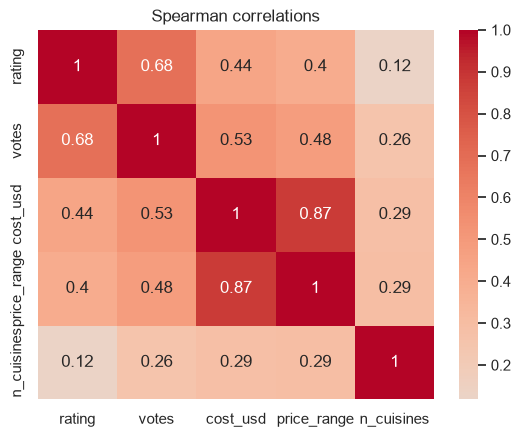

In [96]:
# Correlation: which numbers move together?
# +1 = rise together, -1 = one rises as the other falls, 0 = unrelated.
# "spearman" works on rankings, so extremes don't distort it.
cols = ["rating", "votes", "cost_usd", "price_range", "n_cuisines"]
sns.heatmap(rated[cols].corr(method="spearman"), annot=True,
            cmap="coolwarm", center=0)
plt.title("Spearman correlations")
plt.show()

In [97]:
# NOTE: correlation is not causation. Pricier restaurants rate higher, but that doesn't mean raising prices raises ratings. Maybe better places can charge more. Also, online delivery looks slightly NEGATIVE for ratings, but delivery is much more common in cheap places and in India, so country and price are confounders". That's why careful analysts compare within groups (e.g. the same price range).
print(rated.groupby(["price_range", "has_online_delivery"])["rating"]
           .mean().unstack())

has_online_delivery     False     True 
price_range                            
1                    3.230287  3.261574
2                    3.414325  3.333414
3                    3.832570  3.645477
4                    3.886973  3.930189


## Where the hidden gems are

In [98]:
# PROBLEM: a restaurant with a 4.9 from 5 votes isn't clearly better than one
#          with 4.5 from 2,000 votes. Few votes = unreliable.
# FIX    : "shrink" each rating toward the overall average, more strongly when
#          votes are few. (This is a "Bayesian average", used by IMDb etc.)
overall_mean = rated["rating"].mean()
typical_votes = rated["votes"].median()
v = rated["votes"]
rated["weighted_rating"] = ((v / (v + typical_votes)) * rated["rating"]
                            + (typical_votes / (v + typical_votes)) * overall_mean)

# Hidden gems = high rated but not yet famous (modest number of votes).
gems = rated[(rated["votes"].between(20, 200)) & (rated["rating"] >= 4.2)]
print(gems.sort_values("weighted_rating", ascending=False)
          [["restaurant_name", "city", "primary_cuisine", "rating", "votes"]]
          .head(15))

                     restaurant_name             city primary_cuisine  rating  \
2301       AB's - Absolute Barbecues        Hyderabad        European     4.9   
841                          CakeBee       Coimbatore          Bakery     4.9   
9458                      Urbanologi       Inner City           Tapas     4.9   
9424       Mainland China Restaurant             Doha         Chinese     4.9   
9404                          Solita       Manchester        American     4.9   
9388                             Bao           London       Taiwanese     4.9   
9360               Roseleaf Bar Cafe        Edinburgh        Scottish     4.7   
9524                    Gaga Manjero           Ankara   World Cuisine     4.9   
2456                    Aman Chicken         Ludhiana    North Indian     4.6   
1221                         Pier 38          Gurgaon         Persian     4.6   
9321                      The Hangar  Wellington City            Cafe     4.6   
9484  Restaurant Mosaic @ Th

# Export Cleaned Dataset

In [99]:
df1.drop(columns="cuisine_list").to_csv("sienna_clean.csv", index=False)
print("Saved sienna_clean.csv")

Saved sienna_clean.csv
